# 15 Check against the original 2025 code: the Tule Pond signal from two independent implementations

```
Author: Danielle Lindsay
Environment: opera_disp_feb13. Run time: about 4 min (the 2025 script reads the full descending time series).
```

**What this notebook does.** The cross-fault creep series of this paper (notebook 03) were first computed in February
2025 with a stand-alone script written by DL before any of the code in this repository existed. That script produced
the first version of this result, presented as

> Lindsay, D., Taira, T., & Bürgmann, R. (2025). Seasonal to Multiannual Creep Rate Changes Along the Hayward,
> Rodgers Creek, and Maacama Faults. Poster 079, 2025 SCEC Annual Meeting, SCEC Contribution 14951.
> https://central.scec.org/publication/14951 (poster PDF in the Zenodo data record of this paper).

The script and what survived of its outputs are in `original_2025_code/` (its README lists them). This notebook

1. shows the parts of the 2025 script that do the work (section 2);
2. makes a copy of it that differs only in its input and output paths, in running one frame (HW3, the Tule Pond
   latitudes) and in cropping the repository's whole-fault product to those rows, and prints that difference
   (section 3);
3. runs the copy on the repository's prepared descending product (section 4);
4. compares its east-minus-west series with the notebook 03 series at the same crossings, on the same acquisition
   dates, over the Tule Pond peak-slip band and the whole HW3 span, and measures the step at each of the five archived
   onsets in both (sections 5 and 6);
5. does the same for the surviving February 2025 output table, which was computed from the OPERA DISP-S1 products as
   downloaded in early 2025 (section 7);
6. works out the projection factor the 2025 script used, so its 'fault-parallel' values can be read correctly
   (section 8), and registers the comparison numbers (section 9).

The repository's extraction (notebook 03, `creep_profiles.py`) is the same algorithm as the 2025 script, the median of
the pixels on each side of the trace differenced at every epoch, generalised to two tracks with a pixel-rate mask, the
common date grid and the two-track decomposition. The 2025 script is the simpler statement of it, and it is kept here so
that a reader can see the signal come out of 800 lines of plain code with no shared functions.


## 1. Imports and settings

In [1]:
import os
import sys
import glob
import difflib
import subprocess

import numpy as np                               # Matrix calculations
import pandas as pd                              # Tables
import matplotlib.pyplot as plt

import insar_utils as utils
from TulePond_filepaths import common_paths, paths_out, repo_dir, insar_dic_list

In [2]:
notebook = "15_check_original_2025_code"
out_dir = paths_out[notebook]
fig_dir = common_paths["fig_dir"]
os.makedirs(out_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)

orig_dir = common_paths["original_2025_dir"]                                     # original_2025_code/ in the repository
script_2025 = os.path.join(orig_dir, "HW1_creeprate_2025-02-14.py")              # the Feb 2025 script, verbatim
series_2025_feb = os.path.join(orig_dir, "HW3_west_east_fault_parallel_ts_2025-02.csv")   # its surviving output (early-2025 products)

descending = [dic for dic in insar_dic_list if dic["ORBIT_DIRECTION"] == "descending"][0]   # the track the 2025 work used
los_file = os.path.join(paths_out["03_creep_timeseries"], "creep_ts_LOS_descending.csv")   # notebook 03: east - west LOS per crossing
geom_file = os.path.join(paths_out["03_creep_timeseries"], "creep_geom_descending.csv")    # notebook 03: incidence and azimuth per crossing
events_file = os.path.join(paths_out["04_event_detection"], "creep_events.csv")            # notebook 04: the five onsets
lengths_file = os.path.join(paths_out["04_event_detection"], "section_lengths.csv")        # notebook 04: the 90 % band

hw3_lat = (37.515, 37.695)      # the latitude span of the Feb 2025 HW3 frame crop (its output table runs 37.519-37.690 N)
match_m = 60.0                  # a 2025 crossing is paired with the nearest repository crossing within this distance (m)
step_n = 3                      # step at an onset: mean of the step_n epochs after the window minus the step_n before it
date_tol_d = 3.0                # section 7 only: the Feb 2025 table rounds the decimal year differently; pair dates within this (d)
min_common_epochs = 50          # per-crossing statistics need at least this many common finite epochs

REG = utils.Registry(notebook, common_paths, repo_dir)
REG.inputs(script_2025, series_2025_feb, los_file, geom_file, events_file, lengths_file,
           descending["ts_file"], descending["vel_file"], common_paths["fault_profiles"])

events = pd.read_csv(events_file)
events = events[events.segment == "TULEPOND"].reset_index(drop=True)
assert len(events) == 5, f"expected the five Tule Pond events, found {len(events)}"
onset_lo, onset_hi = events.onset_lo.to_numpy(float), events.onset_hi.to_numpy(float)
band = pd.read_csv(lengths_file).set_index("name").loc["tulepond_band90"]
band_lat = (float(band.lat_lo), float(band.lat_hi))
print(f"Tule Pond 90 % band: {band_lat[0]:.4f}-{band_lat[1]:.4f} N ({band.km_lo:g}-{band.km_hi:g} km); onsets {onset_lo.round(3)}")

Registry for 15_check_original_2025_code: run 3e0d8807, git 3e393bf+
Tule Pond 90 % band: 37.5494-37.5650 N (58.2-60.2 km); onsets [2017.101 2019.187 2021.109 2023.08  2024.986]


## 2. The 2025 script, the parts that do the work

The whole file is `original_2025_code/HW1_creeprate_2025-02-14.py`. Printed here: the parameters, the reader (note the
placeholder look vector, section 8), the projection function, and the core of the loop over the crossings: the pixels
of a crossing are split by their across-fault coordinate `p` into a west and an east subset, each side is reduced to its
median at every epoch, and the two medians are differenced.

In [3]:
lines_2025 = open(script_2025).read().splitlines()
print(f"{os.path.basename(script_2025)}: {len(lines_2025)} lines")


def show(first, last, title):
    print(f"\n----- lines {first}-{last}: {title}")
    for number in range(first, last + 1):
        print(f"{number:4d}  {lines_2025[number - 1]}")


show(56, 60, "the aperture and the point threshold")
show(222, 236, "the reader: the look vector is a placeholder, not read from the geometry files")
show(250, 283, "west and east subsets, and the projection")
show(500, 548, "the loop: medians per side, the difference, the projection of each side")

HW1_creeprate_2025-02-14.py: 805 lines

----- lines 56-60: the aperture and the point threshold
  56  dist_min = 0.1
  57  dist_max = 0.3
  58  x_length = dist_max + 0.1
  59  x_width = 0.2
  60  min_points_threshold = 10 

----- lines 222-236: the reader: the look vector is a placeholder, not read from the geometry files
 222      transformer = Transformer.from_crs("EPSG:32610", "EPSG:4326", always_xy=True)
 223      lons, lats = transformer.transform(utm_x, utm_y)
 224      
 225      # Compute the azimuth and incidence angles from east/north coefficients
 226      east = np.full_like(velocity, 0.65) # Set values fix when I know how to load east and north. 
 227      north = np.full_like(velocity, -0.11)  # Set values fix when I know how to load east and north. 
 228      azi = calc_azimuth_from_east_north_obs(east, north)
 229  
 230      up = np.sqrt(1 - east**2 - north**2)
 231      inc = np.rad2deg(np.arccos(up))
 232  
 233      # Return data as dictionary
 234      return {
 23

## 3. A copy that differs only in paths, the frame list and a row crop

The repository's prepared products cover the whole fault on one grid (3048 by 2333 pixels), whereas the 2025 run read a
frame crop (`timeseries_HW3_msk.h5`). The copy therefore (a) points `base_dir` at a folder of symbolic links named as
the 2025 script expects, (b) runs the HW3 dictionary only, (c) crops the rows to the HW3 latitudes right after reading,
and (d) writes its per-crossing tables to CSV. Nothing in the extraction is touched. The full difference is printed and
saved as `patch.diff`.

In [4]:
inputs_dir = os.path.join(out_dir, "inputs_HW3")
os.makedirs(inputs_dir, exist_ok=True)
for link_name, target in (("velocity_HW3_msk.h5", descending["vel_file"]), ("timeseries_HW3_msk.h5", descending["ts_file"])):
    link = os.path.join(inputs_dir, link_name)
    if os.path.islink(link) or os.path.exists(link):
        os.remove(link)
    os.symlink(target, link)
    print(f"{link_name} -> {target}")


def replace_whole_line(text, old, new):
    # replace the one line that is exactly `old` (not a commented copy of it)
    hits = [line for line in text.splitlines() if line.rstrip() == old]
    assert len(hits) == 1, f"expected one line '{old}', found {len(hits)}"
    return "\n".join(new if line.rstrip() == old else line for line in text.splitlines()) + "\n"


def replace_once(text, old, new):
    assert text.count(old) == 1, f"expected one occurrence of {old[:60]!r}, found {text.count(old)}"
    return text.replace(old, new)


source = open(script_2025).read()
patched = source
# (a) paths
patched = replace_whole_line(patched, 'base_dir = "/Volumes/X10Pro/OPERA/11115_Hayward/mintpy_output"', f'base_dir = "{inputs_dir}"   # PATCH: links to the repository inputs')
patched = replace_whole_line(patched, 'fig_dir = "/Volumes/X10Pro/OPERA/Figures"', f'fig_dir = "{out_dir}"   # PATCH')
patched = replace_whole_line(patched, 'output_dir = "/Volumes/X10Pro/OPERA/Scripts"', f'output_dir = "{out_dir}"   # PATCH')
patched = replace_whole_line(patched, 'fault_profiles = "/Volumes/X10Pro/OPERA/Scripts/CF_HF_cross_profiles_sorted.csv"', f'fault_profiles = "{common_paths["fault_profiles"]}"   # PATCH: the repository trace, same columns')
patched = replace_whole_line(patched, "creep_rate_file='/Users/daniellelindsay/Google Drive/My Drive/Proj_1_MTJ_creeprates/data/SRL-2022186_Supplement_FINAL_2023_CREEP_Dataset.csv'", f"creep_rate_file='{common_paths['creep_rates_Johnson22']}'   # PATCH")
patched = replace_whole_line(patched, 'xfault_csv_path = f"/Volumes/X10Pro/OPERA/11115_Hayward/mintpy_output/{fault_name}_fault_data.csv"', f'xfault_csv_path = f"{out_dir}/{{fault_name}}_fault_data_HW3.csv"   # PATCH')
# (b) one frame
patched = replace_whole_line(patched, "insar_dic_list = [HW1_dic, HW2_dic, HW3_dic, HW4_dic, HW5_dic, HW6_dic]", "insar_dic_list = [HW3_dic]   # PATCH: HW3 (Tule Pond) only")
# (c) crop the rows to the HW3 latitudes after reading
old_block = "    up = np.sqrt(1 - east**2 - north**2)\n    inc = np.rad2deg(np.arccos(up))\n"
new_block = old_block + f"""
    # PATCH: crop to the HW3 rows ({hw3_lat[0]}-{hw3_lat[1]} N, the span of the Feb 2025 HW3 product)
    rows_hw3 = np.where((lats[:, 0] >= {hw3_lat[0]}) & (lats[:, 0] <= {hw3_lat[1]}))[0]
    r0, r1 = rows_hw3.min(), rows_hw3.max() + 1
    velocity, ts, lons, lats, inc, azi = velocity[r0:r1], ts[:, r0:r1], lons[r0:r1], lats[r0:r1], inc[r0:r1], azi[r0:r1]
    print(f"PATCH: cropped to rows {{r0}}:{{r1}} ({{r1 - r0}} rows), lat {{lats.min():.4f}}-{{lats.max():.4f}}")
"""
patched = replace_once(patched, old_block, new_block)
# (d) write the per-crossing tables
patched = replace_once(patched, '    dic["plot_data"] = plot_data_pivot\n',
                       '    dic["plot_data"] = plot_data_pivot\n'
                       '    plot_data_pivot.to_csv(f"{output_dir}/{segment}_west_east_fault_parallel_ts.csv")   # PATCH: the 2025 projected series\n'
                       '    plot_data.pivot(index="latitude", columns="time", values="west_east_ts").to_csv(f"{output_dir}/{segment}_west_east_LOS_ts.csv")   # PATCH: east - west LOS, before the projection\n')

patched_path = os.path.join(out_dir, "HW1_creeprate_2025_patched_HW3.py")
open(patched_path, "w").write(patched)
diff = list(difflib.unified_diff(source.splitlines(), patched.splitlines(), "HW1_creeprate_2025-02-14.py", "HW1_creeprate_2025_patched_HW3.py", lineterm="", n=0))
open(os.path.join(out_dir, "patch.diff"), "w").write("\n".join(diff) + "\n")
removed = sum(1 for line in diff if line.startswith("-") and not line.startswith("---"))
added = sum(1 for line in diff if line.startswith("+") and not line.startswith("+++"))
print(f"\n{removed} lines removed, {added} added, of {len(lines_2025)}:\n")
print("\n".join(diff))

velocity_HW3_msk.h5 -> /Users/dlindsay/work/proj_TulePond_DISP_release/11115/mintpy/velocity_masked.h5
timeseries_HW3_msk.h5 -> /Users/dlindsay/work/proj_TulePond_DISP_release/11115/mintpy/timeseries_tropo.h5

7 lines removed, 15 added, of 805:

--- HW1_creeprate_2025-02-14.py
+++ HW1_creeprate_2025_patched_HW3.py
@@ -65 +65 @@
-base_dir = "/Volumes/X10Pro/OPERA/11115_Hayward/mintpy_output"
+base_dir = "/Users/dlindsay/work/proj_TulePond_DISP_release/outputs/15_check_original_2025_code/inputs_HW3"   # PATCH: links to the repository inputs
@@ -67,3 +67,3 @@
-fig_dir = "/Volumes/X10Pro/OPERA/Figures"
-output_dir = "/Volumes/X10Pro/OPERA/Scripts"
-fault_profiles = "/Volumes/X10Pro/OPERA/Scripts/CF_HF_cross_profiles_sorted.csv"
+fig_dir = "/Users/dlindsay/work/proj_TulePond_DISP_release/outputs/15_check_original_2025_code"   # PATCH
+output_dir = "/Users/dlindsay/work/proj_TulePond_DISP_release/outputs/15_check_original_2025_code"   # PATCH
+fault_profiles = "/Users/dlindsay/work/proj_Tule

## 4. Run it

The copy runs as a separate process with the notebook's Python, so nothing from this notebook is in its namespace. It
prints one line per crossing; the log is kept. The 2025 figures it draws (its Hovmöller diagram and rate profile) are
written to this notebook's output folder.

In [5]:
log_path = os.path.join(out_dir, "run_2025_script.log")
with open(log_path, "w") as log:
    result = subprocess.run([sys.executable, patched_path], cwd=out_dir, env=dict(os.environ, MPLBACKEND="Agg"), stdout=log, stderr=subprocess.STDOUT)
log_text = open(log_path).read()
assert result.returncode == 0, f"the 2025 script failed (exit {result.returncode}); see {log_path}\n" + log_text[-3000:]
n_crossings_tried = log_text.count("Getting points")
n_skipped = log_text.count("Skipping")
print([line for line in log_text.splitlines() if line.startswith("PATCH")][0])
print(f"crossings tried {n_crossings_tried}, skipped {n_skipped}")
los_2025_file = os.path.join(out_dir, "HW3_west_east_LOS_ts.csv")
fp_2025_file = os.path.join(out_dir, "HW3_west_east_fault_parallel_ts.csv")
assert os.path.exists(los_2025_file) and os.path.exists(fp_2025_file), "the 2025 script wrote no series"
print("written:", sorted(os.path.basename(path) for path in glob.glob(os.path.join(out_dir, "HW3_*"))))

PATCH: cropped to rows 1499:2164 (665 rows), lat 37.5092-37.6948
crossings tried 258, skipped 10
written: ['HW3_11115_detrended_fault_parallel.png', 'HW3_11115_west_east_fault_parallel_x_width0.2_dist_min0.1_dist_max0.3_minpoints10.png', 'HW3_west_east_LOS_ts.csv', 'HW3_west_east_fault_parallel_ts.csv']


## 5. Functions: pairing the crossings, stacks, detrending and the step at an onset

Each 2025 crossing is paired with the nearest repository crossing within `match_m`. A stack is the mean over a set of
crossings at every epoch (NaN ignored), zeroed at its first finite epoch. A straight line is removed from each stack
before the two are compared, so the comparison is of the shape of the series, not of the rates, which are reported
separately. The step at an onset is

$$ S = \frac{1}{n}\sum_{t_j \ge t^{hi}} d(t_j)\Big|_{\text{first } n} - \frac{1}{n}\sum_{t_j \le t^{lo}} d(t_j)\Big|_{\text{last } n}, $$

where $d$ is the stack (mm), $t^{lo}$ and $t^{hi}$ the onset window of notebook 04 and $n$ = `step_n`. It is the
same statistic as the detector of notebook 04, applied to both codes identically; it is not the amplitude quoted in the
paper, which comes from the joint model of notebook 04.

In [6]:
def read_series(path):
    table = pd.read_csv(path)
    lat = table.iloc[:, 0].to_numpy(float)
    dates = table.columns[1:].astype(float).to_numpy()
    values = table.iloc[:, 1:].to_numpy(float)
    return lat, dates, values


def pair_crossings(lat_a, lat_b, max_m):
    pairs = []
    for i, lat in enumerate(lat_a):
        k = int(np.argmin(np.abs(lat_b - lat)))
        if abs(lat_b[k] - lat) * 111.2e3 <= max_m:
            pairs.append((i, k))
    return np.array(pairs, dtype=int)


def stack_of(values, rows):
    with np.errstate(all="ignore"):
        stack = np.nanmean(values[rows], axis=0)
    return stack


def detrend(t, y):
    coef = np.polyfit(t, y, 1)
    return y - np.polyval(coef, t), coef[0]


def step_at(t, y, lo, hi, n=step_n):
    before = y[t <= lo][-n:]
    after = y[t >= hi][:n]
    if len(before) < n or len(after) < n:
        return np.nan
    return float(after.mean() - before.mean())


def compare_stacks(t, a, b, label):
    ok = np.isfinite(a) & np.isfinite(b)
    t, a, b = t[ok], a[ok] - a[ok][0], b[ok] - b[ok][0]
    da, rate_a = detrend(t, a)
    db, rate_b = detrend(t, b)
    corr = float(np.corrcoef(da, db)[0, 1])
    rms = float(np.sqrt(np.mean((da - db) ** 2)))
    steps = pd.DataFrame({"onset_lo": onset_lo, "onset_hi": onset_hi,
                          "step_2025_mm": [step_at(t, a, lo, hi) for lo, hi in zip(onset_lo, onset_hi)],
                          "step_repo_mm": [step_at(t, b, lo, hi) for lo, hi in zip(onset_lo, onset_hi)]})
    steps["ratio_2025_over_repo"] = steps.step_2025_mm / steps.step_repo_mm
    print(f"[{label}] epochs {ok.sum()}, span {t[0]:.3f}-{t[-1]:.3f}")
    print(f"   rate: 2025 {rate_a:.2f} mm/yr, repository {rate_b:.2f} mm/yr")
    print(f"   detrended: correlation {corr:.3f}, RMS difference {rms:.2f} mm")
    print(steps.to_string(index=False, float_format=lambda v: f"{v:.2f}"))
    return dict(t=t, a=a, b=b, da=da, db=db, rate_a=rate_a, rate_b=rate_b, corr=corr, rms=rms, steps=steps, n_epochs=int(ok.sum()))

## 6. Same product, two codes

The notebook 03 series are the east-minus-west LOS differences on the descending track (before the two-track
decomposition), on the same acquisition dates as the 2025 run, so the two are paired epoch by epoch with no
interpolation. The apertures differ by design (2025: 0.1 to 0.3 km from the trace, at least 10 pixels per side, no
pixel-rate mask; repository: 0.03 to 0.15 km, at least 5, the rate mask and the coherence-0.7 mask), which is the
aperture dependence that the binning ladder of notebook 05 measures.

In [7]:
lat_2025, dates_2025, los_2025 = read_series(los_2025_file)
lat_repo, dates_repo, los_repo = read_series(los_file)
assert len(dates_2025) == len(dates_repo), (len(dates_2025), len(dates_repo))
assert np.max(np.abs(dates_2025 - dates_repo)) * 365.25 < 2, "the two codes read the same dates: only the decimal-year rounding may differ"
t = dates_repo

pairs = pair_crossings(lat_2025, lat_repo, match_m)
in_band = (lat_2025[pairs[:, 0]] >= band_lat[0]) & (lat_2025[pairs[:, 0]] <= band_lat[1])
print(f"2025 crossings {len(lat_2025)} ({lat_2025.min():.4f}-{lat_2025.max():.4f} N), repository {len(lat_repo)}, paired {len(pairs)}, in the band {in_band.sum()}\n")

same_band = compare_stacks(t, stack_of(los_2025, pairs[in_band, 0]), stack_of(los_repo, pairs[in_band, 1]), "Tule Pond 90 % band, same product")
print()
same_all = compare_stacks(t, stack_of(los_2025, pairs[:, 0]), stack_of(los_repo, pairs[:, 1]), "whole HW3 span, same product")

# crossing by crossing
per_crossing = []
for i, k in pairs:
    a, b = los_2025[i], los_repo[k]
    ok = np.isfinite(a) & np.isfinite(b)
    if ok.sum() < min_common_epochs:
        continue
    da, _ = detrend(t[ok], a[ok])
    db, _ = detrend(t[ok], b[ok])
    per_crossing.append((lat_2025[i], float(np.corrcoef(da, db)[0, 1]), float(np.sqrt(np.mean((da - db) ** 2)))))
per_crossing = pd.DataFrame(per_crossing, columns=["lat", "corr", "rms_mm"])
per_crossing.to_csv(os.path.join(out_dir, "per_crossing_same_product.csv"), index=False)
print(f"\nper crossing ({len(per_crossing)} with >= {min_common_epochs} common epochs): median correlation {per_crossing['corr'].median():.3f} "
      f"(10-90 %: {per_crossing['corr'].quantile(.1):.3f}-{per_crossing['corr'].quantile(.9):.3f}), median RMS {per_crossing.rms_mm.median():.2f} mm")

2025 crossings 248 (37.5116-37.6922 N), repository 629, paired 216, in the band 21

[Tule Pond 90 % band, same product] epochs 374, span 2016.674-2026.218
   rate: 2025 2.70 mm/yr, repository 2.56 mm/yr
   detrended: correlation 0.973, RMS difference 0.44 mm
 onset_lo  onset_hi  step_2025_mm  step_repo_mm  ratio_2025_over_repo
  2017.10   2017.13          4.03          5.19                  0.78
  2019.19   2019.20          5.20          5.70                  0.91
  2021.11   2021.13          3.64          4.92                  0.74
  2023.08   2023.11          4.35          4.70                  0.93
  2024.99   2025.02          3.11          3.84                  0.81

[whole HW3 span, same product] epochs 374, span 2016.674-2026.218
   rate: 2025 2.82 mm/yr, repository 2.84 mm/yr
   detrended: correlation 0.876, RMS difference 0.24 mm
 onset_lo  onset_hi  step_2025_mm  step_repo_mm  ratio_2025_over_repo
  2017.10   2017.13          0.74          1.02                  0.73
  2019.19 

## 7. The surviving February 2025 table

`HW3_west_east_fault_parallel_ts_2025-02.csv` is the output of the same script in February 2025, from the OPERA DISP-S1
products as downloaded then (300 epochs to August 2024) and projected with the 2025 factor of section 8. Here it is
multiplied back by that factor to return it to the LOS difference, and compared with the repository over the common span.
Dates are paired to within `date_tol_d`; the December 2024 onset is after this table ends.

In [8]:
lat_feb, dates_feb, fp_feb = read_series(series_2025_feb)
pairs_feb = pair_crossings(lat_feb, lat_repo, match_m)
in_band_feb = (lat_feb[pairs_feb[:, 0]] >= band_lat[0]) & (lat_feb[pairs_feb[:, 0]] <= band_lat[1])

# pair the Feb 2025 epochs with the repository epochs
epoch_pairs = []
for j, date in enumerate(dates_feb):
    k = int(np.argmin(np.abs(dates_repo - date)))
    if abs(dates_repo[k] - date) * 365.25 <= date_tol_d:
        epoch_pairs.append((j, k))
epoch_pairs = np.array(epoch_pairs, dtype=int)
print(f"Feb 2025 table: {len(lat_feb)} crossings ({lat_feb.min():.4f}-{lat_feb.max():.4f} N), {len(dates_feb)} epochs {dates_feb[0]:.3f}-{dates_feb[-1]:.3f}; "
      f"paired crossings {len(pairs_feb)} (in the band {in_band_feb.sum()}), paired epochs {len(epoch_pairs)}\n")

# the placeholder look vector and the projection vector of the 2025 script (section 8 explains them)
east_ph, north_ph = 0.65, -0.11
look_ph = np.array([east_ph, north_ph, np.sqrt(1 - east_ph**2 - north_ph**2)])
strike = float(np.mean(pd.read_csv(common_paths["fault_profiles"]).profile_az) + 90)   # as notebook 02: mean cross-fault azimuth + 90
aspect_called = strike                                                 # the loop passed profile_az + 90, the strike
aspect_converted = -aspect_called + 90                                 # the function's conversion
vector_2025 = np.array([-np.sin(np.deg2rad(aspect_converted)), np.cos(np.deg2rad(aspect_converted)), 0.0])   # slope 90: horizontal
factor_feb = float(look_ph @ vector_2025)
los_feb = fp_feb * factor_feb                                          # back to the LOS difference
t_feb = dates_repo[epoch_pairs[:, 1]]
feb_band = compare_stacks(t_feb, stack_of(los_feb, pairs_feb[in_band_feb, 0])[epoch_pairs[:, 0]],
                          stack_of(los_repo, pairs_feb[in_band_feb, 1])[epoch_pairs[:, 1]], "Tule Pond 90 % band, Feb 2025 table (early-2025 products) vs repository")

Feb 2025 table: 194 crossings (37.5185-37.6896 N), 300 epochs 2016.608-2024.592; paired crossings 183 (in the band 20), paired epochs 299

[Tule Pond 90 % band, Feb 2025 table (early-2025 products) vs repository] epochs 299, span 2016.674-2024.591
   rate: 2025 2.46 mm/yr, repository 2.47 mm/yr
   detrended: correlation 0.975, RMS difference 0.49 mm
 onset_lo  onset_hi  step_2025_mm  step_repo_mm  ratio_2025_over_repo
  2017.10   2017.13          3.83          5.09                  0.75
  2019.19   2019.20          4.87          5.64                  0.86
  2021.11   2021.13          3.71          4.89                  0.76
  2023.08   2023.11          4.25          4.63                  0.92
  2024.99   2025.02           NaN           NaN                   NaN


/var/folders/bz/z50q20pn1fsbtbkbs0bcrqf00000gp/T/ipykernel_42995/359614496.py:20: RuntimeWarning: Mean of empty slice
  stack = np.nanmean(values[rows], axis=0)


## 8. The projection factor of the 2025 script

Two things in the 2025 script set its 'fault-parallel' scale, and both are kept as they were. The reader did not load
the geometry files: the look vector is the placeholder $(e, n) = (0.65, -0.11)$ for every pixel, $u = \sqrt{1 - e^2 - n^2}$.
And `los2fault_projection` converts its `aspect` to anticlockwise-from-east ($90^\circ - \text{aspect}$) and then uses
a formula written for an angle anticlockwise from north; the loop passed it `profile_az + 90`, the strike $\Psi$, so the
unit vector it projected onto has bearing $\Psi - 90$, across the fault, not along it. The factor it divided by is

$$ G_{2025} = \hat{\mathbf{l}}_{ph} \cdot \hat{\mathbf{n}}, \qquad \hat{\mathbf{n}} = (\sin(\Psi - 90^\circ), \cos(\Psi - 90^\circ), 0), $$

against the repository's $G = \hat{\mathbf{l}} \cdot \hat{\mathbf{s}}$ with the true look vector per crossing and the
strike unit vector $\hat{\mathbf{s}}$ (`insar_utils.design_matrix_up_fp`, tested against MintPy in
`tests/test_insar_utils.py`, and against the 2025 functions in `tests/test_original_2025_code.py`). Their ratio is the
constant by which the 2025 'fault-parallel' values differ from the repository's single-track fault-parallel values on
this descending track. The east-minus-west LOS difference compared above does not involve either factor.

In [9]:
geom = pd.read_csv(geom_file)
in_band_geom = (geom.lat >= band_lat[0]) & (geom.lat <= band_lat[1])
factor_repo = float(np.mean([utils.design_matrix_up_fp([inc], [azi], strike)[0, 1] for inc, azi in zip(geom.inc_deg[in_band_geom], geom.azi_deg[in_band_geom])]))
inc_ph = float(np.degrees(np.arccos(look_ph[2])))
bearing_2025 = float(np.degrees(np.arctan2(vector_2025[0], vector_2025[1])) % 360)
print(f"placeholder look vector: east {east_ph}, north {north_ph}, up {look_ph[2]:.3f} (incidence {inc_ph:.1f} deg); "
      f"true in the band: incidence {geom.inc_deg[in_band_geom].mean():.1f} deg, azimuth {geom.azi_deg[in_band_geom].mean():.1f} deg")
print(f"projection vector the 2025 script used: bearing {bearing_2025:.1f} deg (the strike is {strike:.1f})")
print(f"2025 factor {factor_feb:.4f}; repository fault-parallel factor {factor_repo:.4f}; 2025 'fault-parallel' = repository x {factor_repo / factor_feb:.3f}")

placeholder look vector: east 0.65, north -0.11, up 0.752 (incidence 41.2 deg); true in the band: incidence 43.2 deg, azimuth 260.4 deg
projection vector the 2025 script used: bearing 54.1 deg (the strike is 144.1)
2025 factor 0.4622; repository fault-parallel factor 0.4883; 2025 'fault-parallel' = repository x 1.056


## 9. Figure and registry

The figure shows the two stacks over the Tule Pond band from the same product (section 6), their detrended versions and
the difference, with the five onset windows shaded. The registry rows `15_*` and the sidecar `15_check_original_2025_code_stats.txt`
hold every number above.

figure: /Users/dlindsay/work/proj_TulePond_DISP_release/Figures_2026-11-01/figS_check_original_2025_code.png


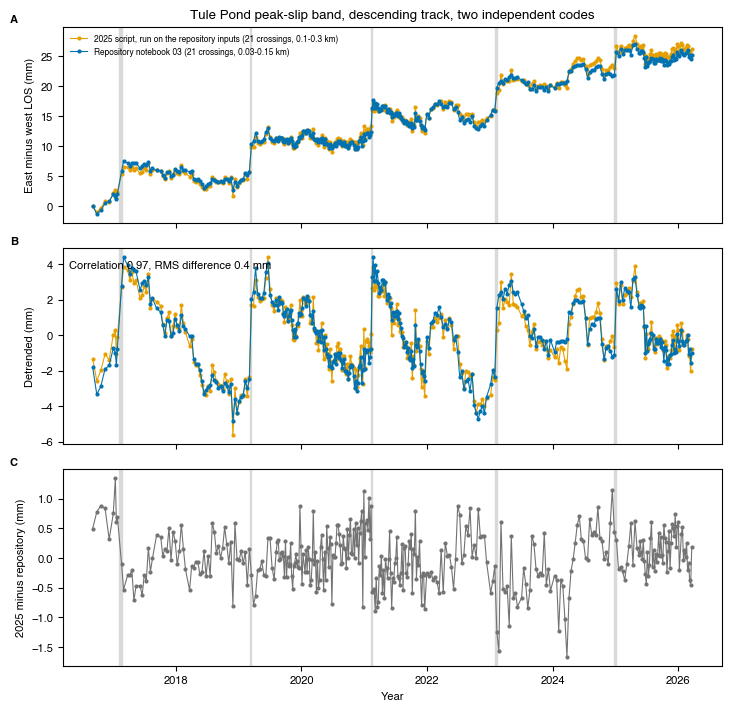

In [10]:
utils.mpl_paper_style(base=8)
blue, orange, grey = "#0072B2", "#E69F00", "0.45"           # Okabe-Ito blue and orange
fig, axes = plt.subplots(3, 1, figsize=(7.2, 7.0), sharex=True, constrained_layout=True)
s = same_band
axes[0].plot(s["t"], s["a"], "-o", ms=2, lw=0.8, color=orange, label=f"2025 script, run on the repository inputs ({in_band.sum()} crossings, 0.1-0.3 km)")
axes[0].plot(s["t"], s["b"], "-o", ms=2, lw=0.8, color=blue, label=f"Repository notebook 03 ({in_band.sum()} crossings, 0.03-0.15 km)")
axes[0].set_ylabel("East minus west LOS (mm)")
axes[0].legend(loc="upper left", frameon=False)
axes[0].set_title("Tule Pond peak-slip band, descending track, two independent codes")
axes[1].plot(s["t"], s["da"], "-o", ms=2, lw=0.8, color=orange)
axes[1].plot(s["t"], s["db"], "-o", ms=2, lw=0.8, color=blue)
axes[1].set_ylabel("Detrended (mm)")
axes[1].text(0.01, 0.9, f"Correlation {s['corr']:.2f}, RMS difference {s['rms']:.1f} mm", transform=axes[1].transAxes)
axes[2].plot(s["t"], s["da"] - s["db"], "-o", ms=2, lw=0.8, color=grey)
axes[2].set_ylabel("2025 minus repository (mm)")
axes[2].set_xlabel("Year")
for ax, letter in zip(axes, "ABC"):
    for lo, hi in zip(onset_lo, onset_hi):
        ax.axvspan(lo, hi, color="0.85", zorder=0)
    ax.text(-0.08, 1.02, letter, transform=ax.transAxes, fontweight="bold")
fig_path = os.path.join(fig_dir, "figS_check_original_2025_code.png")
fig.savefig(fig_path, dpi=300)
print("figure:", fig_path)

In [11]:
stats_lines = [f"15 CHECK AGAINST THE ORIGINAL 2025 CODE  (descending {descending['Frame']}, HW3 rows {hw3_lat[0]}-{hw3_lat[1]} N, band {band_lat[0]:.4f}-{band_lat[1]:.4f} N)",
               f"2025 script: {os.path.basename(script_2025)}, {len(lines_2025)} lines; patch {removed} lines removed, {added} added (paths, one frame, row crop, two to_csv)",
               f"crossings: 2025 {len(lat_2025)}, repository {len(lat_repo)}, paired within {match_m:g} m {len(pairs)}, in the band {in_band.sum()}",
               "SAME PRODUCT, TULE POND BAND (east - west LOS, same dates):",
               f"   rate 2025 {same_band['rate_a']:.2f} mm/yr, repository {same_band['rate_b']:.2f} mm/yr; detrended correlation {same_band['corr']:.3f}, RMS {same_band['rms']:.2f} mm, epochs {same_band['n_epochs']}",
               "   steps at the five onsets (mm, 3 after minus 3 before): " + ", ".join(f"{a:.2f}/{b:.2f}" for a, b in zip(same_band['steps'].step_2025_mm, same_band['steps'].step_repo_mm)) + "  (2025/repository)",
               f"   mean step ratio 2025/repository {same_band['steps'].ratio_2025_over_repo.mean():.3f}",
               "SAME PRODUCT, WHOLE HW3 SPAN:",
               f"   rate 2025 {same_all['rate_a']:.2f}, repository {same_all['rate_b']:.2f} mm/yr; correlation {same_all['corr']:.3f}, RMS {same_all['rms']:.2f} mm",
               f"   per crossing (n {len(per_crossing)}): median correlation {per_crossing['corr'].median():.3f}, median RMS {per_crossing.rms_mm.median():.2f} mm",
               "FEB 2025 TABLE (early-2025 products, to 2024.59), TULE POND BAND:",
               f"   rate 2025 {feb_band['rate_a']:.2f}, repository {feb_band['rate_b']:.2f} mm/yr; correlation {feb_band['corr']:.3f}, RMS {feb_band['rms']:.2f} mm, epochs {feb_band['n_epochs']}",
               "   steps at the onsets inside the table (mm): " + ", ".join(f"{a:.2f}/{b:.2f}" for a, b in zip(feb_band['steps'].step_2025_mm, feb_band['steps'].step_repo_mm) if np.isfinite(a)),
               "PROJECTION FACTOR OF THE 2025 SCRIPT:",
               f"   placeholder look vector east {east_ph} north {north_ph} (incidence {inc_ph:.1f} deg); projection bearing {bearing_2025:.1f} deg (strike {strike:.1f})",
               f"   2025 factor {factor_feb:.4f}, repository {factor_repo:.4f}, 2025 fault-parallel = repository x {factor_repo / factor_feb:.3f}",
               f"figure: {os.path.basename(fig_path)}; log: {os.path.basename(log_path)}; patch: patch.diff"]
print("\n".join(stats_lines))
sidecar = REG.sidecar("15_check_original_2025_code", stats_lines)
n_steps_2025 = int((same_band["steps"].step_2025_mm > 2.0).sum())    # onsets at which the 2025 series steps by more than 2 mm (LOS)
REG.register("15_n_paired_crossings", len(pairs), "count", 0, where="M3", cell="pairing", sidecar=sidecar)
REG.register("15_n_band_crossings", int(in_band.sum()), "count", 0, where="M3", cell="pairing", sidecar=sidecar)
REG.register("15_band_corr", same_band["corr"], "1", 3, where="M3", cell="same product", sidecar=sidecar)
REG.register("15_band_rms_mm", same_band["rms"], "mm", 2, where="M3", cell="same product", sidecar=sidecar)
REG.register("15_band_rate_2025_mm_yr", same_band["rate_a"], "mm/yr", 2, where="M3", cell="same product", sidecar=sidecar)
REG.register("15_band_rate_repo_mm_yr", same_band["rate_b"], "mm/yr", 2, where="M3", cell="same product", sidecar=sidecar)
REG.register("15_band_step_ratio_mean", same_band["steps"].ratio_2025_over_repo.mean(), "1", 3, where="M3", cell="same product", sidecar=sidecar)
REG.register("15_n_onsets_stepping_in_2025", n_steps_2025, "count", 0, where="M3", cell="same product", sidecar=sidecar)
REG.register("15_all_corr", same_all["corr"], "1", 3, where="M3", cell="same product", sidecar=sidecar)
REG.register("15_all_rms_mm", same_all["rms"], "mm", 2, where="M3", cell="same product", sidecar=sidecar)
REG.register("15_per_crossing_median_corr", per_crossing["corr"].median(), "1", 3, where="M3", cell="same product", sidecar=sidecar)
REG.register("15_feb2025_band_corr", feb_band["corr"], "1", 3, where="M3", cell="feb 2025 table", sidecar=sidecar)
REG.register("15_feb2025_band_rms_mm", feb_band["rms"], "mm", 2, where="M3", cell="feb 2025 table", sidecar=sidecar)
REG.register("15_factor_2025", factor_feb, "1", 4, where="M3", cell="projection", sidecar=sidecar)
REG.register("15_factor_repo", factor_repo, "1", 4, where="M3", cell="projection", sidecar=sidecar)
REG.render()

15 CHECK AGAINST THE ORIGINAL 2025 CODE  (descending 11115, HW3 rows 37.515-37.695 N, band 37.5494-37.5650 N)
2025 script: HW1_creeprate_2025-02-14.py, 805 lines; patch 7 lines removed, 15 added (paths, one frame, row crop, two to_csv)
crossings: 2025 248, repository 629, paired within 60 m 216, in the band 21
SAME PRODUCT, TULE POND BAND (east - west LOS, same dates):
   rate 2025 2.70 mm/yr, repository 2.56 mm/yr; detrended correlation 0.973, RMS 0.44 mm, epochs 374
   steps at the five onsets (mm, 3 after minus 3 before): 4.03/5.19, 5.20/5.70, 3.64/4.92, 4.35/4.70, 3.11/3.84  (2025/repository)
   mean step ratio 2025/repository 0.834
SAME PRODUCT, WHOLE HW3 SPAN:
   rate 2025 2.82, repository 2.84 mm/yr; correlation 0.876, RMS 0.24 mm
   per crossing (n 216): median correlation 0.674, median RMS 1.03 mm
FEB 2025 TABLE (early-2025 products, to 2024.59), TULE POND BAND:
   rate 2025 2.46, repository 2.47 mm/yr; correlation 0.975, RMS 0.49 mm, epochs 299
   steps at the onsets inside t

  registered 15_band_corr = 0.973 1  -> M3
  registered 15_band_rms_mm = 0.44 mm  -> M3
  registered 15_band_rate_2025_mm_yr = 2.70 mm/yr  -> M3
  registered 15_band_rate_repo_mm_yr = 2.56 mm/yr  -> M3
  registered 15_band_step_ratio_mean = 0.834 1  -> M3
  registered 15_n_onsets_stepping_in_2025 = 5 count  -> M3
  registered 15_all_corr = 0.876 1  -> M3
  registered 15_all_rms_mm = 0.24 mm  -> M3


  registered 15_per_crossing_median_corr = 0.674 1  -> M3
  registered 15_feb2025_band_corr = 0.975 1  -> M3
  registered 15_feb2025_band_rms_mm = 0.49 mm  -> M3
  registered 15_factor_2025 = 0.4622 1  -> M3
  registered 15_factor_repo = 0.4883 1  -> M3


Wrote the numbers to: /Users/dlindsay/work/proj_TulePond_DISP_release/outputs/paper_numbers.md


'/Users/dlindsay/work/proj_TulePond_DISP_release/outputs/paper_numbers.md'